# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# import the necessary libraries

# Load and Explore the Dataset


In [2]:
pip install split-folders

Note: you may need to restart the kernel to use updated packages.


In [3]:
import splitfolders as sf

sf.ratio(
    input = '/kaggle/input/datasets/orvile/eye-diseases-classification/Image Dataset on Eye Diseases Classification (Uveitis, Conjunctivitis, Cataract, Eyelid) with Symptoms and SMOTE Validation' ,
    output = 'Dataset' ,
    ratio = (0.7,0.2,0.1) ,
    seed = 42
)

# use splitfolders to split the dataset folder into train,val and test sets

Copying files: 2298 files [00:13, 173.43 files/s]


In [4]:
train_dir = '/kaggle/working/Dataset/train'
valid_dir = '/kaggle/working/Dataset/val'
test_dir = '/kaggle/working/Dataset/test'

# define dataset paths

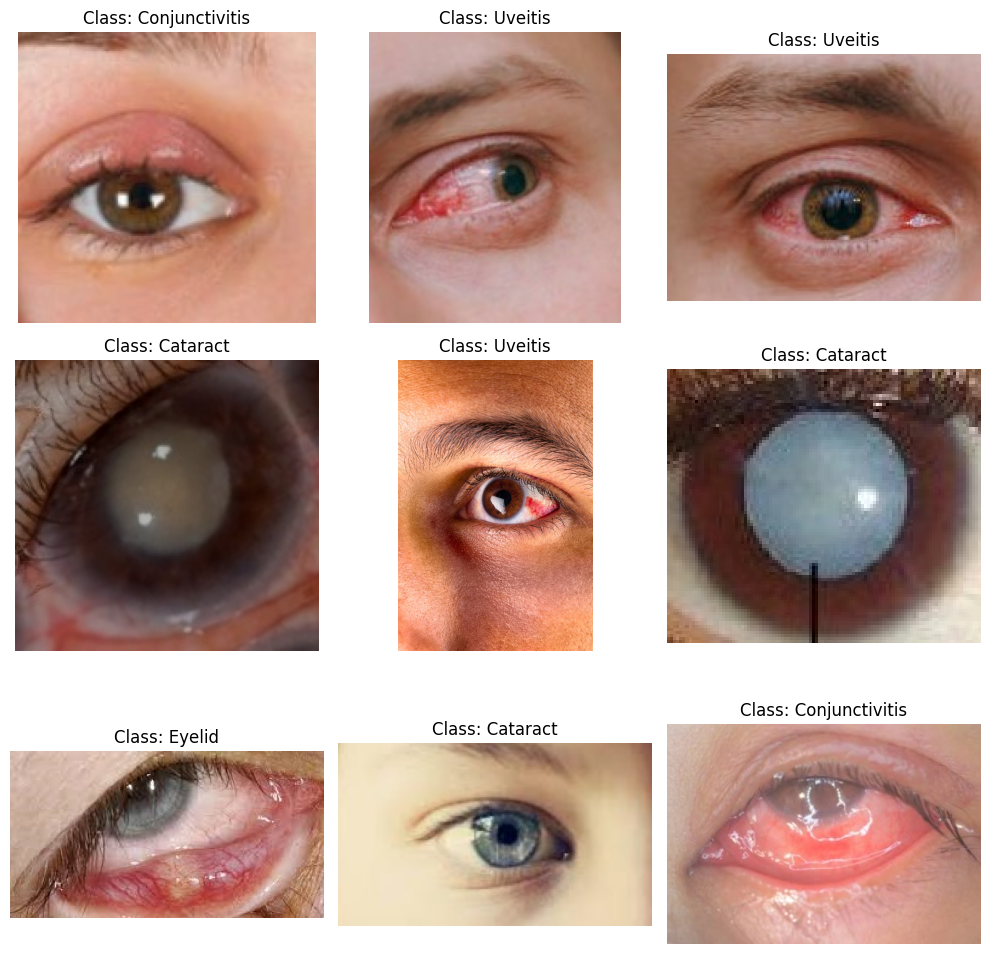

In [5]:
import os
import random

class_names = sorted(os.listdir(train_dir))

def show_sample_images(dataset_path, class_names, n=9):

    plt.figure(figsize=(10,10))

    for i in range(n):
        class_name = random.choice(class_names)
        class_path = os.path.join(dataset_path, class_name)

        img_name = random.choice(os.listdir(class_path))
        img_path = os.path.join(class_path, img_name)

        img = plt.imread(img_path)

        plt.subplot(3,3,i+1)
        plt.imshow(img)
        plt.title(f"Class: {class_name}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_sample_images(train_dir, class_names)

# visualize sample images from the dataset

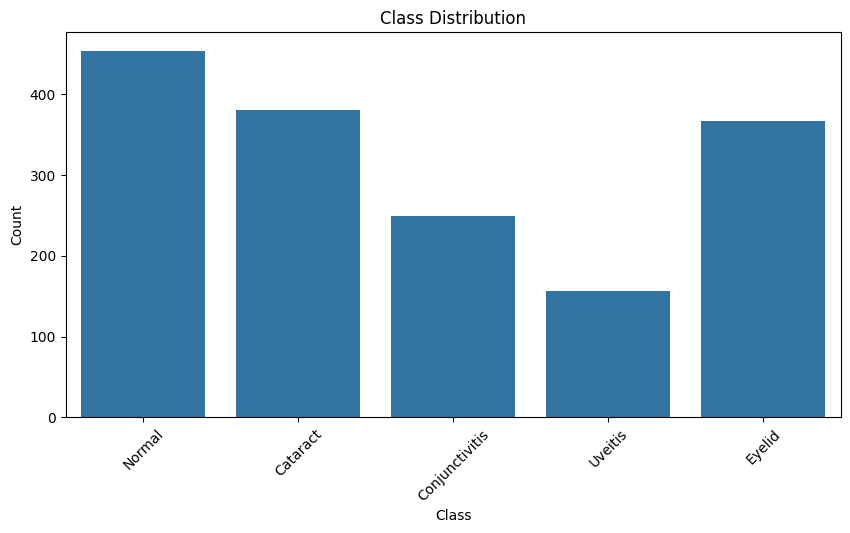

In [6]:
class_counts = {}

for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)
    class_counts[class_name] = len(os.listdir(class_path))

df = pd.DataFrame(list(class_counts.items()), columns=["Class","Count"])

plt.figure(figsize=(10,5))
sns.barplot(x="Class", y="Count", data=df)
plt.title("Class Distribution")
plt.xticks(rotation=45)
plt.show()

# check class distribution

# Data Preprocessing & Data Augmentation


In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

train_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input ,
    width_shift_range = 0.2 ,
    height_shift_range = 0.2 ,
    zoom_range = 0.2 ,
    rotation_range = 30 ,
    fill_mode = 'nearest'
)

valid_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

# apply data augmentation

In [8]:
train = train_datagen.flow_from_directory(
    train_dir,
    target_size = (224,224) ,
    class_mode = 'categorical' ,
    seed = 42 ,
    batch_size = 32 ,
    shuffle = True
)

valid = valid_datagen.flow_from_directory(
    valid_dir,
    target_size = (224,224) ,
    class_mode = 'categorical' ,
    seed = 42 ,
    batch_size = 32 ,
    shuffle = False
)

test = test_datagen.flow_from_directory(
    test_dir,
    target_size = (224,224) ,
    class_mode = 'categorical' ,
    seed = 42 ,
    batch_size = 32 ,
    shuffle = False
)

Found 1606 images belonging to 5 classes.
Found 457 images belonging to 5 classes.
Found 235 images belonging to 5 classes.


# Build the Model

In [9]:
from keras.applications import EfficientNetB0

base = EfficientNetB0(
    weights = 'imagenet' ,
    include_top = False ,
    input_shape = (224,224,3)
)

base.trainable = False

# using transfer learning

I0000 00:00:1785585059.064835      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [10]:
from keras.models import Sequential
from keras.layers import Dense , Dropout , GlobalAvgPool2D

Model = Sequential()

Model.add(base)

Model.add(GlobalAvgPool2D())

Model.add(Dense(256,activation='relu'))
Model.add(Dropout(0.4))

Model.add(Dense(128,activation='relu'))
Model.add(Dropout(0.4))

Model.add(Dense(5,activation='softmax'))

# build the model architecture

In [11]:
from keras.optimizers import AdamW

Model.compile(optimizer=AdamW(learning_rate=0.0001,weight_decay=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

# compile the model

In [12]:
from keras.callbacks import EarlyStopping

EarlyStop = EarlyStopping (
    monitor = 'val_loss' ,
    patience = 5 ,
    restore_best_weights = True
)

# using EarlyStopping to prevent overfitting 

In [13]:
from keras.callbacks import ReduceLROnPlateau

ReduceLR = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,       
    patience=4,       
    verbose=1,         
    min_lr=1e-6
)

# using ReduceLROnPlateau to reduce learning rate when validation loss stops improving

In [14]:
Model.fit(train,validation_data=valid,epochs=20,callbacks=[EarlyStop,ReduceLR])

# train the model

Epoch 1/20


I0000 00:00:1785585087.997568      98 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


51/51 ━━━━━━━━━━━━━━━━━━━━ 66s 845ms/step - accuracy: 0.4035 - loss: 1.4310 - val_accuracy: 0.5077 - val_loss: 1.3030 - learning_rate: 1.0000e-04
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 17s 332ms/step - accuracy: 0.6071 - loss: 1.0650 - val_accuracy: 0.6411 - val_loss: 1.0901 - learning_rate: 1.0000e-04
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 17s 326ms/step - accuracy: 0.6725 - loss: 0.9022 - val_accuracy: 0.7133 - val_loss: 0.9076 - learning_rate: 1.0000e-04
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 17s 344ms/step - accuracy: 0.7323 - loss: 0.7888 - val_accuracy: 0.7637 - val_loss: 0.7553 - learning_rate: 1.0000e-04
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 17s 331ms/step - accuracy: 0.7403 - loss: 0.7337 - val_accuracy: 0.8009 - val_loss: 0.6664 - learning_rate: 1.0000e-04
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 17s 326ms/step - accuracy: 0.7740 - loss: 0.6398 - val_accuracy: 0.8162 - val_loss: 0.5983 - learning_rate: 1.0000e-04
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 17s 327ms/step - accuracy: 0.78

# Evaluate the Model

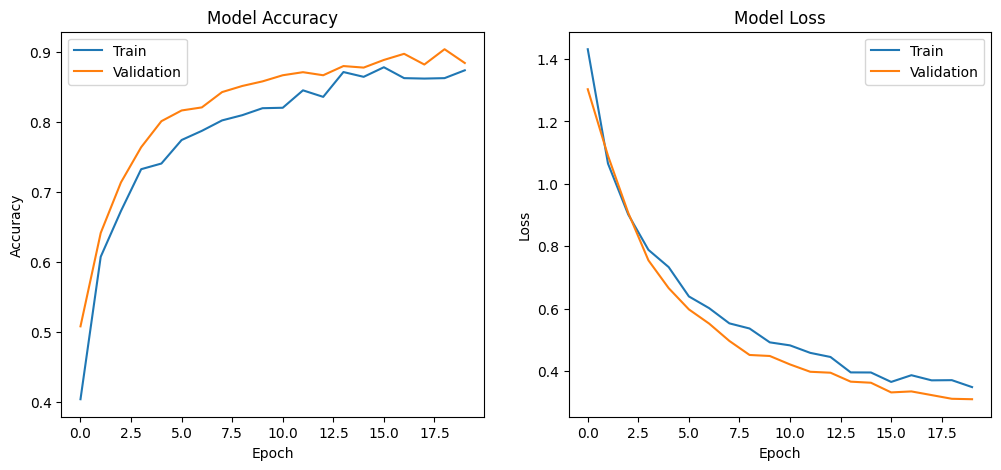

In [15]:
History = pd.DataFrame(Model.history.history)

plt.figure(figsize=(12,5))

# accuracy
plt.subplot(1,2,1)
plt.plot(History["accuracy"])
plt.plot(History["val_accuracy"])
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["Train","Validation"])

# loss
plt.subplot(1,2,2)
plt.plot(History["loss"])
plt.plot(History["val_loss"])
plt.title("Model Loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["Train","Validation"])

plt.show()

# visualize training history

In [16]:
y_pred_prob = Model.predict(test)

y_pred = np.argmax(y_pred_prob,axis=1)

y_true = test.classes

8/8 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step


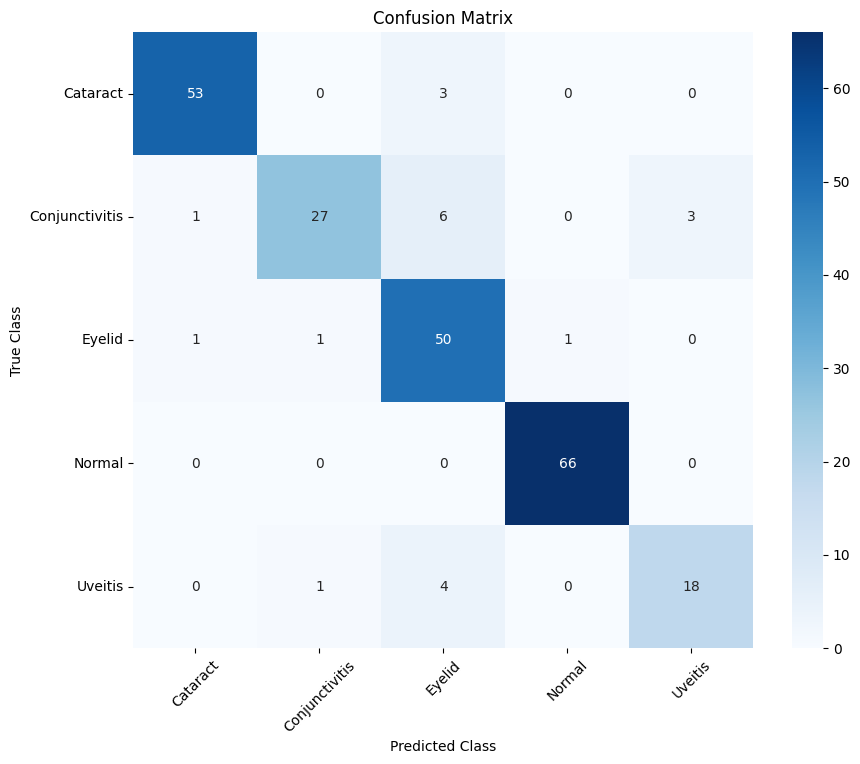

In [17]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)


plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

# generate confusion matrix

In [18]:
from sklearn.metrics import classification_report

print(classification_report(y_true,y_pred))

# generate classification report

              precision    recall  f1-score   support

           0       0.96      0.95      0.95        56
           1       0.93      0.73      0.82        37
           2       0.79      0.94      0.86        53
           3       0.99      1.00      0.99        66
           4       0.86      0.78      0.82        23

    accuracy                           0.91       235
   macro avg       0.91      0.88      0.89       235
weighted avg       0.92      0.91      0.91       235

